# P2.13 — What wages and mortgage rates could finance

**Question:** RQ9.4 (how much of price growth do fundamentals explain, and how much is left for investment demand and
expectations?). Builds on `p2_08` (rates), `p2_09` (wages) and `p2_12` (credit).

A buyer who spends a fixed share of the average wage on a loan covering a fixed share of the price can afford
`wage / payment per euro borrowed`: the implied price rises with wages and falls with the rate. The gap between the actual
price and that benchmark is what wages and rates do not account for. It is not "expectations" or "speculation": it also holds
credit rationing (the loan may not be granted), buyers richer than the average employee, foreign and cash buyers, scarce supply
and anything else. The level of the burden is not observed, so only changes in the gap carry information. National, annual,
nominal, 2003 to 2025.

In [1]:
import pandas as pd

from pthousing.analysis import lending, macro
from pthousing.config import PROCESSED
from pthousing.data import interim
from pthousing.viz import charts, style

style.apply_style()
long = pd.read_parquet(PROCESSED / "national_annual_long.parquet")
annual = macro.annual_frame(long, interim.read("eurostat_macro"))
mortgage = interim.read("bp_mortgage")
frame = macro.financeable_price(annual, macro.annual_rates(mortgage))
print(f"{frame.index.min()}-{frame.index.max()}, {len(frame)} years")
style.save_table(frame.round(2).reset_index(), "p2", "financeable_price")
frame[["price_b2015", "implied_price_b2015", "rate_pct", "gap_pct", "payment_to_wage_b2015"]].round(
    1
)

2003-2025, 23 years


,price_b2015,implied_price_b2015,rate_pct,gap_pct,payment_to_wage_b2015
year,,,,,
2003,108.6,89.0,3.8,19.9,154.8
2004,109.3,96.0,3.4,13.1,144.6
2005,111.8,101.8,3.3,9.4,139.4
2006,114.1,95.8,4.0,17.5,151.1
2007,114.7,90.2,4.8,24.1,161.4
2008,107.5,86.0,5.4,22.3,158.6
2009,106.5,122.4,2.7,-13.9,110.4
2010,107.3,129.8,2.4,-19.0,104.9
2011,102.1,108.0,3.7,-5.7,119.9


## Step 1 — What moved the price in each episode
Episodes are the turning points of the gap and of the rate: the run-up to 2007, the crisis to 2013, the recovery as rates fell
to 2021, and the years since the rate shock. Log points, so the parts add up.

,price_change_pct,wages_pct,rate_pct,gap_pct,span
run-up,5.500676,13.017405,-11.707954,4.191225,2003-2007
crisis,-20.922404,6.047785,18.327807,-45.297995,2007-2013
"recovery, falling rates",59.541069,18.386005,35.312854,5.842209,2013-2021
rate shock,44.644318,27.095416,-32.905088,50.453990,2021-2025


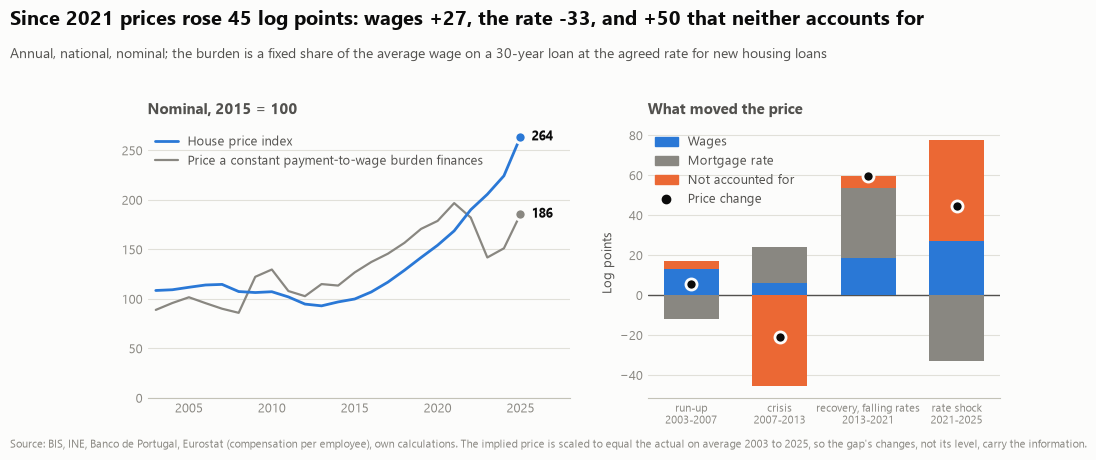

In [2]:
spans = {
    "run-up": (2003, 2007),
    "crisis": (2007, 2013),
    "recovery, falling rates": (2013, 2021),
    "rate shock": (2021, 2025),
}
parts = pd.DataFrame(
    {name: macro.price_change_parts(frame, a, b) for name, (a, b) in spans.items()}
).T
parts["span"] = [f"{a}-{b}" for a, b in spans.values()]
fig = charts.financeable_prices(frame, parts)
style.save_fig(fig, "p2", "financeable_prices")
style.save_table(
    parts.round({"price_change_pct": 1, "wages_pct": 1, "rate_pct": 1, "gap_pct": 1}).reset_index(
        names="episode"
    ),
    "p2",
    "price_change_parts",
)
parts

## Step 2 — Does the reading survive other choices?
The rate (the agreed rate on floating loans, APRC including charges), the loan term (30 years, 20 and 40) and the window on
which the benchmark is set equal to the price (2003-2025, the recovery years 2013-2019, the pre-crisis years 2003-2007).
The gap's rise 2021 to 2025 is the number to watch. One more variant lets the loan term follow the observed mean term of new housing
loans (Banco de Portugal, `p2_22`: 33.2 years in 2021 to 31.9 in 2025; held at the 2018 value of 33.1 before 2018, so only the changes
after 2018 count): the terms of lending are then in the benchmark, not in the gap.

In [3]:
rate_aprc = macro.annual_rates(mortgage, "mortgage_aprc_new_pct")
rate_main = macro.annual_rates(mortgage)
terms = lending.standards_by_year(lending.read_series())["maturity_weighted_mean"]
variants = {
    "main: agreed rate, 30 years, base 2003-2025": dict(rates=rate_main),
    "APRC": dict(rates=rate_aprc),
    "20-year loan": dict(rates=rate_main, term_years=20),
    "40-year loan": dict(rates=rate_main, term_years=40),
    "observed mean term of new loans": dict(rates=rate_main, terms=terms),
    "base 2013-2019": dict(rates=rate_main, base=(2013, 2019)),
    "base 2003-2007": dict(rates=rate_main, base=(2003, 2007)),
}
rows = {}
for name, kw in variants.items():
    f = macro.financeable_price(annual, **kw)
    p = macro.price_change_parts(f, 2021, 2025)
    rows[name] = {
        "gap_2007_pct": f.loc[2007, "gap_pct"],
        "gap_2013_pct": f.loc[2013, "gap_pct"],
        "gap_2021_pct": f.loc[2021, "gap_pct"],
        "gap_2025_pct": f.loc[2025, "gap_pct"],
        "gap_rise_2013_2021_pct": macro.price_change_parts(f, 2013, 2021)["gap_pct"],
        "gap_rise_2021_2025_pct": p["gap_pct"],
        "rate_part_2021_2025_pct": p["rate_pct"],
    }
robust = pd.DataFrame(rows).T
style.save_table(robust.round(1).reset_index(names="variant"), "p2", "financeable_price_variants")
robust.round(1)

,gap_2007_pct,gap_2013_pct,gap_2021_pct,gap_2025_pct,gap_rise_2013_2021_pct,gap_rise_2021_2025_pct,rate_part_2021_2025_pct
"main: agreed rate, 30 years, base 2003-2025",24.1,-21.2,-15.4,35.1,5.8,50.5,-32.9
APRC,17.2,-23.9,-4.0,42.8,20.0,46.8,-29.2
20-year loan,17.4,-22.8,-6.1,34.2,16.7,40.3,-22.7
40-year loan,29.9,-19.7,-23.9,36.0,-4.3,59.9,-42.4
base 2013-2019,44.9,-0.4,5.4,55.9,5.8,50.5,-32.9
base 2003-2007,7.3,-38.0,-32.2,18.3,5.8,50.5,-32.9


## Key numbers

In [4]:
for name, row in parts.iterrows():
    print(
        f"{name} {row['span']}: price {row['price_change_pct']:+.0f} log points = wages {row['wages_pct']:+.0f}, "
        f"rate {row['rate_pct']:+.0f}, not accounted for {row['gap_pct']:+.0f}"
    )
print(
    f"payment-to-wage of buying at the index price (2015 = 100): {frame.loc[2021, 'payment_to_wage_b2015']:.0f} in 2021, "
    f"{frame.loc[2025, 'payment_to_wage_b2015']:.0f} in 2025; 2007 {frame.loc[2007, 'payment_to_wage_b2015']:.0f}, 2013 {frame.loc[2013, 'payment_to_wage_b2015']:.0f}"
)
print(
    f"gap rise 2021 to 2025 across variants: {robust['gap_rise_2021_2025_pct'].min():.0f} to {robust['gap_rise_2021_2025_pct'].max():.0f} log points"
)
print(
    f"rate {frame.loc[2021, 'rate_pct']:.1f}% (2021), {frame.loc[2025, 'rate_pct']:.1f}% (2025); wages {frame['wage_eur'].loc[2021]:,.0f} to {frame['wage_eur'].loc[2025]:,.0f} euros"
)

run-up 2003-2007: price +6 log points = wages +13, rate -12, not accounted for +4
crisis 2007-2013: price -21 log points = wages +6, rate +18, not accounted for -45
recovery, falling rates 2013-2021: price +60 log points = wages +18, rate +35, not accounted for +6
rate shock 2021-2025: price +45 log points = wages +27, rate -33, not accounted for +50
payment-to-wage of buying at the index price (2015 = 100): 109 in 2021, 180 in 2025; 2007 161, 2013 103
gap rise 2021 to 2025 across variants: 40 to 60 log points
rate 0.7% (2021), 3.1% (2025); wages 24,841 to 32,572 euros
